In [1]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

ROOT = Path(
    r"../dataset/plantvillage/PlantVillage/PlantVillage"
)

classes = sorted([
    folder.name
    for folder in ROOT.iterdir()
    if folder.is_dir()
])

print("Number of classes:", len(classes))
print("\nClasses:")

for i, class_name in enumerate(classes):
    print(i, class_name)

Number of classes: 15

Classes:
0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 Potato___Early_blight
3 Potato___Late_blight
4 Potato___healthy
5 Tomato_Bacterial_spot
6 Tomato_Early_blight
7 Tomato_Late_blight
8 Tomato_Leaf_Mold
9 Tomato_Septoria_leaf_spot
10 Tomato_Spider_mites_Two_spotted_spider_mite
11 Tomato__Target_Spot
12 Tomato__Tomato_YellowLeaf__Curl_Virus
13 Tomato__Tomato_mosaic_virus
14 Tomato_healthy


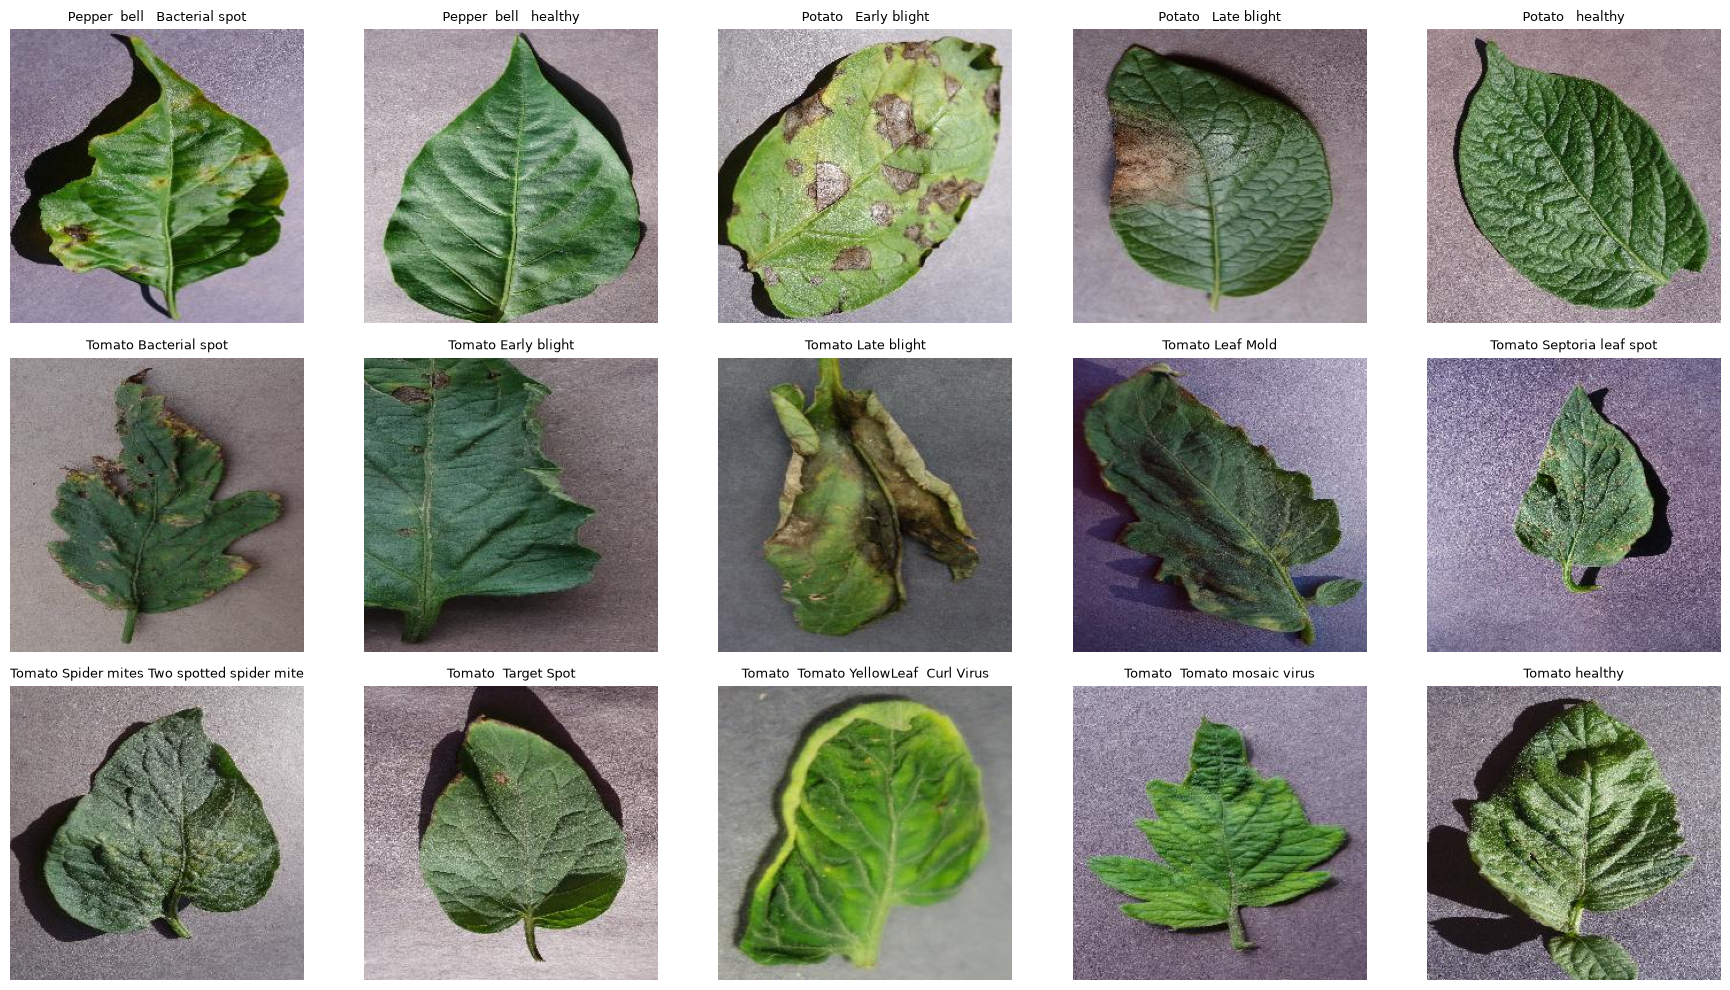

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))

for i, class_name in enumerate(classes):
    class_path = ROOT / class_name

    image_files = [
        p for p in class_path.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    image_path = random.choice(image_files)

    image = Image.open(image_path).convert("RGB")

    ax = axes[i // 5, i % 5]
    ax.imshow(image)
    ax.set_title(class_name.replace("_", " "), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [3]:
from collections import Counter

image_sizes = Counter()

for class_name in classes:
    class_path = ROOT / class_name

    for image_path in class_path.iterdir():
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            try:
                with Image.open(image_path) as img:
                    image_sizes[img.size] += 1
            except Exception:
                pass

print("Unique image dimensions:", len(image_sizes))

print("\nMost common dimensions:")
for size, count in image_sizes.most_common(15):
    print(f"{size}: {count} images")

Unique image dimensions: 1

Most common dimensions:
(256, 256): 20638 images


In [4]:
from collections import Counter

channel_counts = Counter()

sample_count = 0

for class_name in classes:
    class_path = ROOT / class_name

    for image_path in class_path.iterdir():
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            try:
                with Image.open(image_path) as img:
                    channel_counts[img.mode] += 1
                    sample_count += 1
            except Exception:
                pass

print("Image modes:")
for mode, count in channel_counts.items():
    print(f"{mode}: {count}")

print(f"\nTotal checked: {sample_count}")

Image modes:
RGB: 20637
RGBA: 1

Total checked: 20638


In [5]:
image = Image.open(image_path).convert("RGB")